In [20]:
!pip install segmentation-models-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 KB 7.5 MB/s eta 0:00:00


In [21]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp


from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

from datasets import load_dataset
from tqdm import tqdm

In [2]:
#Device 
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [22]:
IMG_SIZE = 512

BATCH_SIZE = 4
NUM_WORKERS = 4

NUM_EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

THRESHOLD = 0.5

MODEL_PATH = "best_unet_vegann.pth"
HISTORY_PATH = "unet_training_history.csv"

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

Image size: 512
Batch size: 4
Epochs: 15


In [4]:
#Loading VegAnn and creating dataset split 
dataset = load_dataset("simonMadec/VegAnn")

split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42,
    shuffle=True
)

train_hf = split_dataset["train"]
val_hf = split_dataset["test"]

print("Train images:", len(train_hf))
print("Validation images:", len(val_hf))
print("Sample keys:", train_hf[0].keys())

Train images: 3020
Validation images: 755
Sample keys: dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [5]:
#Verifying VegAnn mask cnversion 
sample = train_hf[0]

image_np = np.array(sample["image"])
mask_np = np.array(sample["mask"])

print("Image shape:", image_np.shape)
print("Mask shape:", mask_np.shape)
print("Mask unique values:", np.unique(mask_np))

Image shape: (512, 512, 3)
Mask shape: (512, 512)
Mask unique values: [  0 255]


In [6]:
#applying random splits to mask and image 
class VegAnnSegmentationDataset(Dataset):
    def __init__(
        self,
        hf_dataset,
        image_size=512,
        augment=False
    ):
        self.dataset = hf_dataset
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]

        image = sample["image"].convert("RGB")
        mask = sample["mask"]

        image = TF.resize(
            image,
            [self.image_size, self.image_size],
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            [self.image_size, self.image_size],
            interpolation=InterpolationMode.NEAREST
        )

        if self.augment:
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            if random.random() < 0.5:
                image = TF.vflip(image)
                mask = TF.vflip(mask)

        image = TF.to_tensor(image)

        image = TF.normalize(
            image,
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

        mask = np.array(mask)

        # VegAnn foreground/vegetation = 0
        mask = (mask == 0).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return {
            "image": image,
            "mask": mask,
            "index": idx
        }

In [7]:
#creating train and validation datasets 
train_dataset = VegAnnSegmentationDataset(
    train_hf,
    image_size=IMG_SIZE,
    augment=True
)

val_dataset = VegAnnSegmentationDataset(
    val_hf,
    image_size=IMG_SIZE,
    augment=False
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Train dataset: 3020
Validation dataset: 755


In [8]:
#creating Dataloaders 

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    drop_last=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 755
Validation batches: 189


In [9]:
#checking one processed batch 
batch = next(iter(train_loader))

print("Image batch:", batch["image"].shape)
print("Mask batch:", batch["mask"].shape)
print("Mask values:", torch.unique(batch["mask"]))

Image batch: torch.Size([4, 3, 512, 512])
Mask batch: torch.Size([4, 1, 512, 512])
Mask values: tensor([0., 1.])


In [23]:
#Initializing UNET model 
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Model: U-Net + ResNet34")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Model: U-Net + ResNet34
Total parameters: 24,436,369
Trainable parameters: 24,436,369


In [24]:
#BCE and Dice loss functions 
dice_loss_fn = smp.losses.DiceLoss(
    mode="binary",
    from_logits=True
)

def combined_loss(logits, targets):
    return dice_loss_fn(logits, targets)

In [14]:
#mIoU and Dice functions 

def batch_iou_dice(
    logits,
    targets,
    threshold=0.5,
    smooth=1e-6
):
    probabilities = torch.sigmoid(logits)
    predictions = probabilities >= threshold
    targets = targets >= 0.5

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        predictions & targets
    ).sum(dim=1).float()

    union = (
        predictions | targets
    ).sum(dim=1).float()

    pred_sum = predictions.sum(dim=1).float()
    target_sum = targets.sum(dim=1).float()

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    dice = (
        2 * intersection + smooth
    ) / (
        pred_sum + target_sum + smooth
    )

    return iou, dice

In [25]:
#Optimizer, scheduler and AMP 

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = None

"""scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)"""

amp_enabled = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

print("AMP enabled:", amp_enabled)

AMP enabled: True


In [26]:
#Train one epoch 
def train_one_epoch(model, loader, optimizer, scaler):
    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / len(loader.dataset)

    return epoch_loss

In [27]:
#Validation function 
@torch.no_grad()
def validate_model(model, loader):
    model.eval()

    running_loss = 0.0

    all_ious = []
    all_dices = []

    progress_bar = tqdm(
        loader,
        desc="Validation",
        leave=False
    )

    for batch in progress_bar:
        images = batch["image"].to(
            device,
            non_blocking=True
        )

        masks = batch["mask"].to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=amp_enabled
        ):
            logits = model(images)
            loss = combined_loss(logits, masks)

        ious, dices = batch_iou_dice(
            logits,
            masks,
            threshold=THRESHOLD
        )

        running_loss += loss.item() * images.size(0)

        all_ious.extend(
            ious.cpu().numpy().tolist()
        )

        all_dices.extend(
            dices.cpu().numpy().tolist()
        )

    val_loss = running_loss / len(loader.dataset)
    mean_iou = float(np.mean(all_ious))
    mean_dice = float(np.mean(all_dices))

    return val_loss, mean_iou, mean_dice

In [29]:
#Full training loop 
history = []

best_val_iou = -1.0
training_start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scaler
    )

    val_loss, val_iou, val_dice = validate_model(
        model,
        val_loader
    )

    #scheduler.step(val_iou)
    if scheduler is not None:
        scheduler.step(val_iou)

    current_lr = optimizer.param_groups[0]["lr"]
    epoch_time = time.time() - epoch_start

    history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation IoU": val_iou,
        "Validation Dice": val_dice,
        "Learning Rate": current_lr,
        "Epoch Time Seconds": epoch_time
    })

    if val_iou > best_val_iou:
        best_val_iou = val_iou

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_iou": best_val_iou,
                "config": {
                    "image_size": IMG_SIZE,
                    "batch_size": BATCH_SIZE,
                    "epochs": NUM_EPOCHS,
                    "learning_rate": LEARNING_RATE,
                    "seed": SEED
                }
            },
            MODEL_PATH
        )

        saved_message = " — saved best model"
    else:
        saved_message = ""

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"IoU: {val_iou*100:.2f}% | "
        f"Dice: {val_dice*100:.2f}% | "
        f"LR: {current_lr:.2e}"
        f"{saved_message}"
    )

total_training_time = time.time() - training_start

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

print()
print(
    "Total training time:",
    f"{total_training_time / 60:.2f} minutes"
)
print(
    "Best validation IoU:",
    f"{best_val_iou*100:.2f}%"
)

Epoch 01/15 | Train Loss: 0.2111 | Val Loss: 0.1408 | IoU: 64.08% | Dice: 72.24% | LR: 1.00e-04 — saved best model


Epoch 02/15 | Train Loss: 0.1452 | Val Loss: 0.1384 | IoU: 67.20% | Dice: 75.38% | LR: 1.00e-04 — saved best model


Epoch 03/15 | Train Loss: 0.1337 | Val Loss: 0.1182 | IoU: 68.42% | Dice: 76.52% | LR: 1.00e-04 — saved best model


Epoch 04/15 | Train Loss: 0.1276 | Val Loss: 0.1191 | IoU: 67.41% | Dice: 75.45% | LR: 1.00e-04


Epoch 05/15 | Train Loss: 0.1224 | Val Loss: 0.1170 | IoU: 68.05% | Dice: 76.27% | LR: 1.00e-04


Epoch 06/15 | Train Loss: 0.1190 | Val Loss: 0.1164 | IoU: 67.75% | Dice: 75.61% | LR: 1.00e-04


... (5 outputs left out)

Epoch 12/15 | Train Loss: 0.1034 | Val Loss: 0.1064 | IoU: 68.61% | Dice: 76.50% | LR: 1.00e-04


Epoch 13/15 | Train Loss: 0.1024 | Val Loss: 0.0950 | IoU: 69.56% | Dice: 77.38% | LR: 1.00e-04 — saved best model


Epoch 14/15 | Train Loss: 0.1021 | Val Loss: 0.1007 | IoU: 69.36% | Dice: 77.34% | LR: 1.00e-04


Epoch 15/15 | Train Loss: 0.1010 | Val Loss: 0.1046 | IoU: 69.71% | Dice: 77.62% | LR: 1.00e-04 — saved best model

Total training time: 7.29 minutes
Best validation IoU: 69.71%


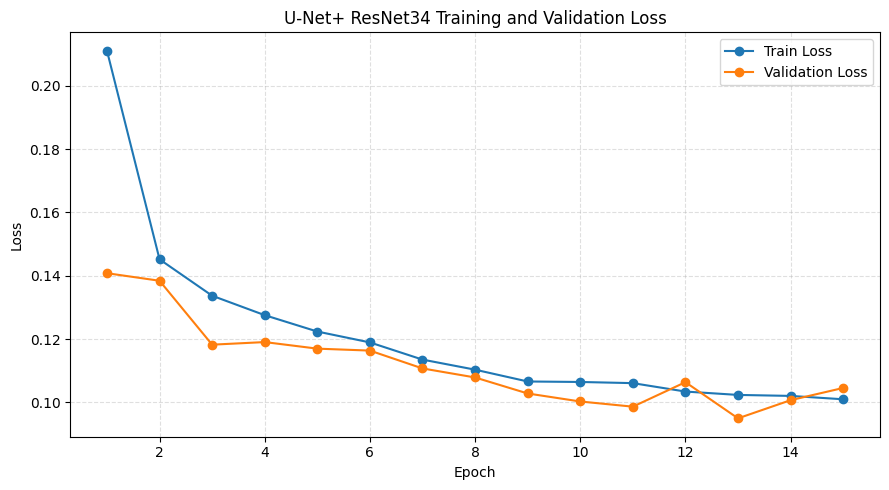

In [42]:
#Plot training and validation loss 
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net+ ResNet34 Training and Validation Loss")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(
    "unet_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

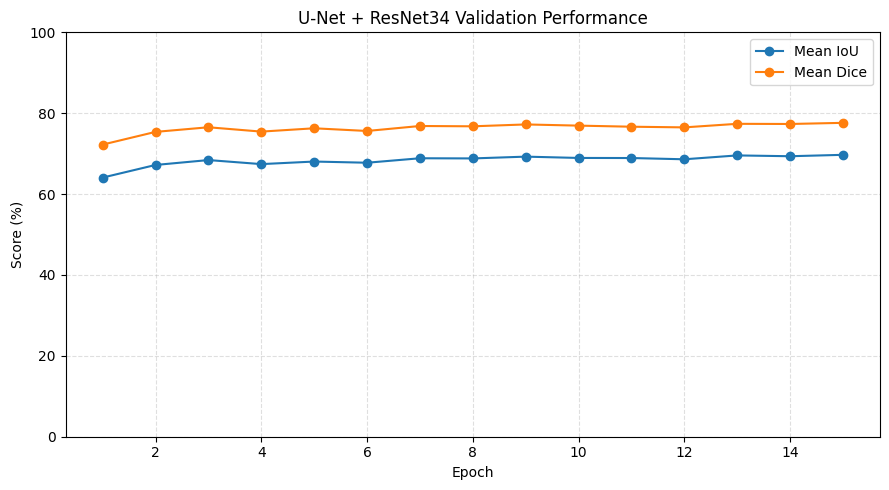

In [43]:
#plot validaion IoU and Dice 
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Validation IoU"] * 100,
    marker="o",
    label="Mean IoU"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Dice"] * 100,
    marker="o",
    label="Mean Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("U-Net + ResNet34 Validation Performance")
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()

plt.savefig(
    "unet_iou_dice_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
#Loading the best checkpoint 

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print(
    "Best saved IoU:",
    f"{checkpoint['best_val_iou']*100:.2f}%"
)

Loaded epoch: 15
Best saved IoU: 69.71%


In [33]:
#Final validation evaluation 
final_val_loss, final_mean_iou, final_mean_dice = validate_model(
    model,
    val_loader
)

print(f"Final Validation Loss: {final_val_loss:.4f}")
print(f"Final Mean IoU: {final_mean_iou*100:.2f}%")
print(f"Final Mean Dice: {final_mean_dice*100:.2f}%")


Final Validation Loss: 0.1046
Final Mean IoU: 69.71%
Final Mean Dice: 77.62%


In [44]:
#Final results table 

unet_results = pd.DataFrame({
    "Method": [
        "U-Net + ResNet34"
    ],
    "Training Regime": [
        "Fully supervised"
    ],
    "Dataset": [
        "VegAnn"
    ],
    "Train Images": [
        len(train_dataset)
    ],
    "Validation Images": [
        len(val_dataset)
    ],
    "Image Size": [
        IMG_SIZE
    ],
    "Epochs": [
        checkpoint["epoch"]
    ],
    "Parameters": [
        total_params
    ],
    "Mean IoU (%)": [
        final_mean_iou * 100
    ],
    "Mean Dice (%)": [
        final_mean_dice * 100
    ],
    "Training Time (min)": [
        total_training_time / 60
    ]
})

unet_results

,Method,Training Regime,Dataset,Train Images,Validation Images,Image Size,Epochs,Parameters,Mean IoU (%),Mean Dice (%),Training Time (min)
0,U-Net + ResNet34,Fully supervised,VegAnn,3020,755,512,15,24436369,69.709265,77.618373,7.290826


In [45]:
#Percentage table 
unet_results_display = unet_results.copy()

unet_results_display["Mean IoU (%)"] = (
    unet_results_display["Mean IoU (%)"]
    .map(lambda x: f"{x:.2f}%")
)

unet_results_display["Mean Dice (%)"] = (
    unet_results_display["Mean Dice (%)"]
    .map(lambda x: f"{x:.2f}%")
)

unet_results_display

,Method,Training Regime,Dataset,Train Images,Validation Images,Image Size,Epochs,Parameters,Mean IoU (%),Mean Dice (%),Training Time (min)
0,U-Net + ResNet34,Fully supervised,VegAnn,3020,755,512,15,24436369,69.71%,77.62%,7.290826


In [47]:
#Saving results 
unet_results.to_csv(
    "unet_vegann_results.csv",
    index=False
)

print("Saved U-Net results.")

Saved U-Net results.


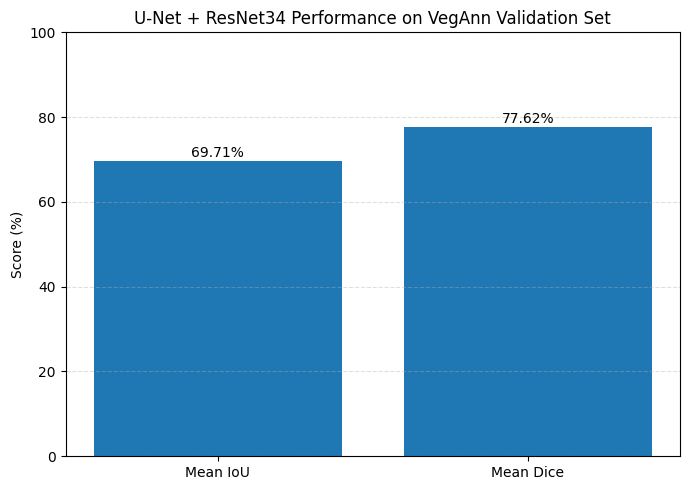

In [46]:
#Plotting final U-Net metrics 
metric_names = [
    "Mean IoU",
    "Mean Dice"
]

metric_values = [
    final_mean_iou * 100,
    final_mean_dice * 100
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylabel("Score (%)")
plt.title("U-Net + ResNet34 Performance on VegAnn Validation Set")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "unet_final_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
#Prediction helper 
@torch.no_grad()
def predict_single_image(model, dataset, idx):
    model.eval()

    item = dataset[idx]

    image_tensor = item["image"].unsqueeze(0).to(device)
    gt_mask = item["mask"].squeeze(0).numpy().astype(bool)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=amp_enabled
    ):
        logits = model(image_tensor)

    probability = torch.sigmoid(logits)[0, 0]
    pred_mask = (
        probability >= THRESHOLD
    ).cpu().numpy()

    original_sample = val_hf[idx]
    original_image = np.array(
        original_sample["image"].convert("RGB")
    )

    original_image = np.array(
        Image.fromarray(original_image).resize(
            (IMG_SIZE, IMG_SIZE)
        )
    )

    intersection = np.logical_and(
        pred_mask,
        gt_mask
    ).sum()

    union = np.logical_or(
        pred_mask,
        gt_mask
    ).sum()

    iou = (
        intersection / union
        if union > 0
        else 0.0
    )

    dice_denominator = (
        pred_mask.sum() + gt_mask.sum()
    )

    dice = (
        2 * intersection / dice_denominator
        if dice_denominator > 0
        else 0.0
    )

    return (
        original_image,
        gt_mask,
        pred_mask,
        iou,
        dice
    )

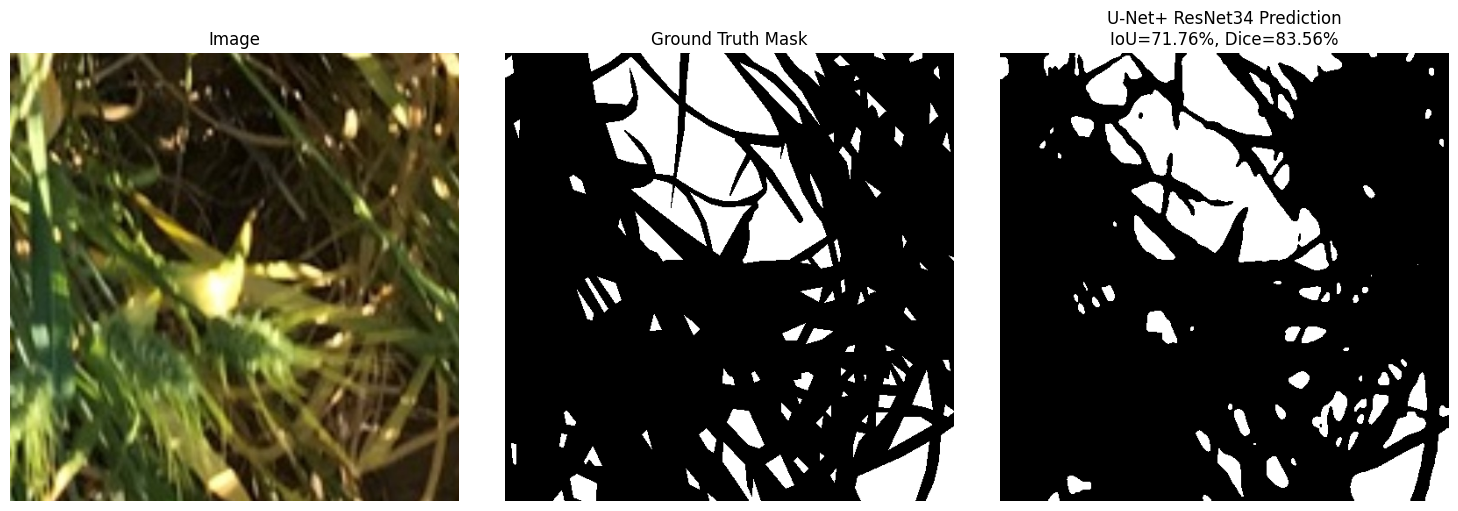

In [48]:
#Visualize 
visual_idx = 0

image_vis, gt_vis, pred_vis, sample_iou, sample_dice = (
    predict_single_image(
        model,
        val_dataset,
        visual_idx
    )
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_vis)
plt.title("Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gt_vis, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_vis, cmap="gray")
plt.title(
    f"U-Net+ ResNet34 Prediction\n"
    f"IoU={sample_iou*100:.2f}%, "
    f"Dice={sample_dice*100:.2f}%"
)
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "unet_image_gt_prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
#Find best median and worst validation examples 
@torch.no_grad()
def collect_validation_predictions(model, dataset):
    records = []

    for idx in tqdm(
        range(len(dataset)),
        desc="Collecting predictions"
    ):
        _, _, _, iou, dice = predict_single_image(
            model,
            dataset,
            idx
        )

        records.append({
            "Index": idx,
            "IoU": iou,
            "Dice": dice
        })

    return pd.DataFrame(records)


prediction_records = collect_validation_predictions(
    model,
    val_dataset
)

prediction_records = prediction_records.sort_values(
    "IoU"
).reset_index(drop=True)

worst_idx = int(
    prediction_records.iloc[0]["Index"]
)

median_idx = int(
    prediction_records.iloc[
        len(prediction_records) // 2
    ]["Index"]
)

best_idx = int(
    prediction_records.iloc[-1]["Index"]
)

print("Worst index:", worst_idx)
print("Median index:", median_idx)
print("Best index:", best_idx)

Worst index: 599
Median index: 341
Best index: 429


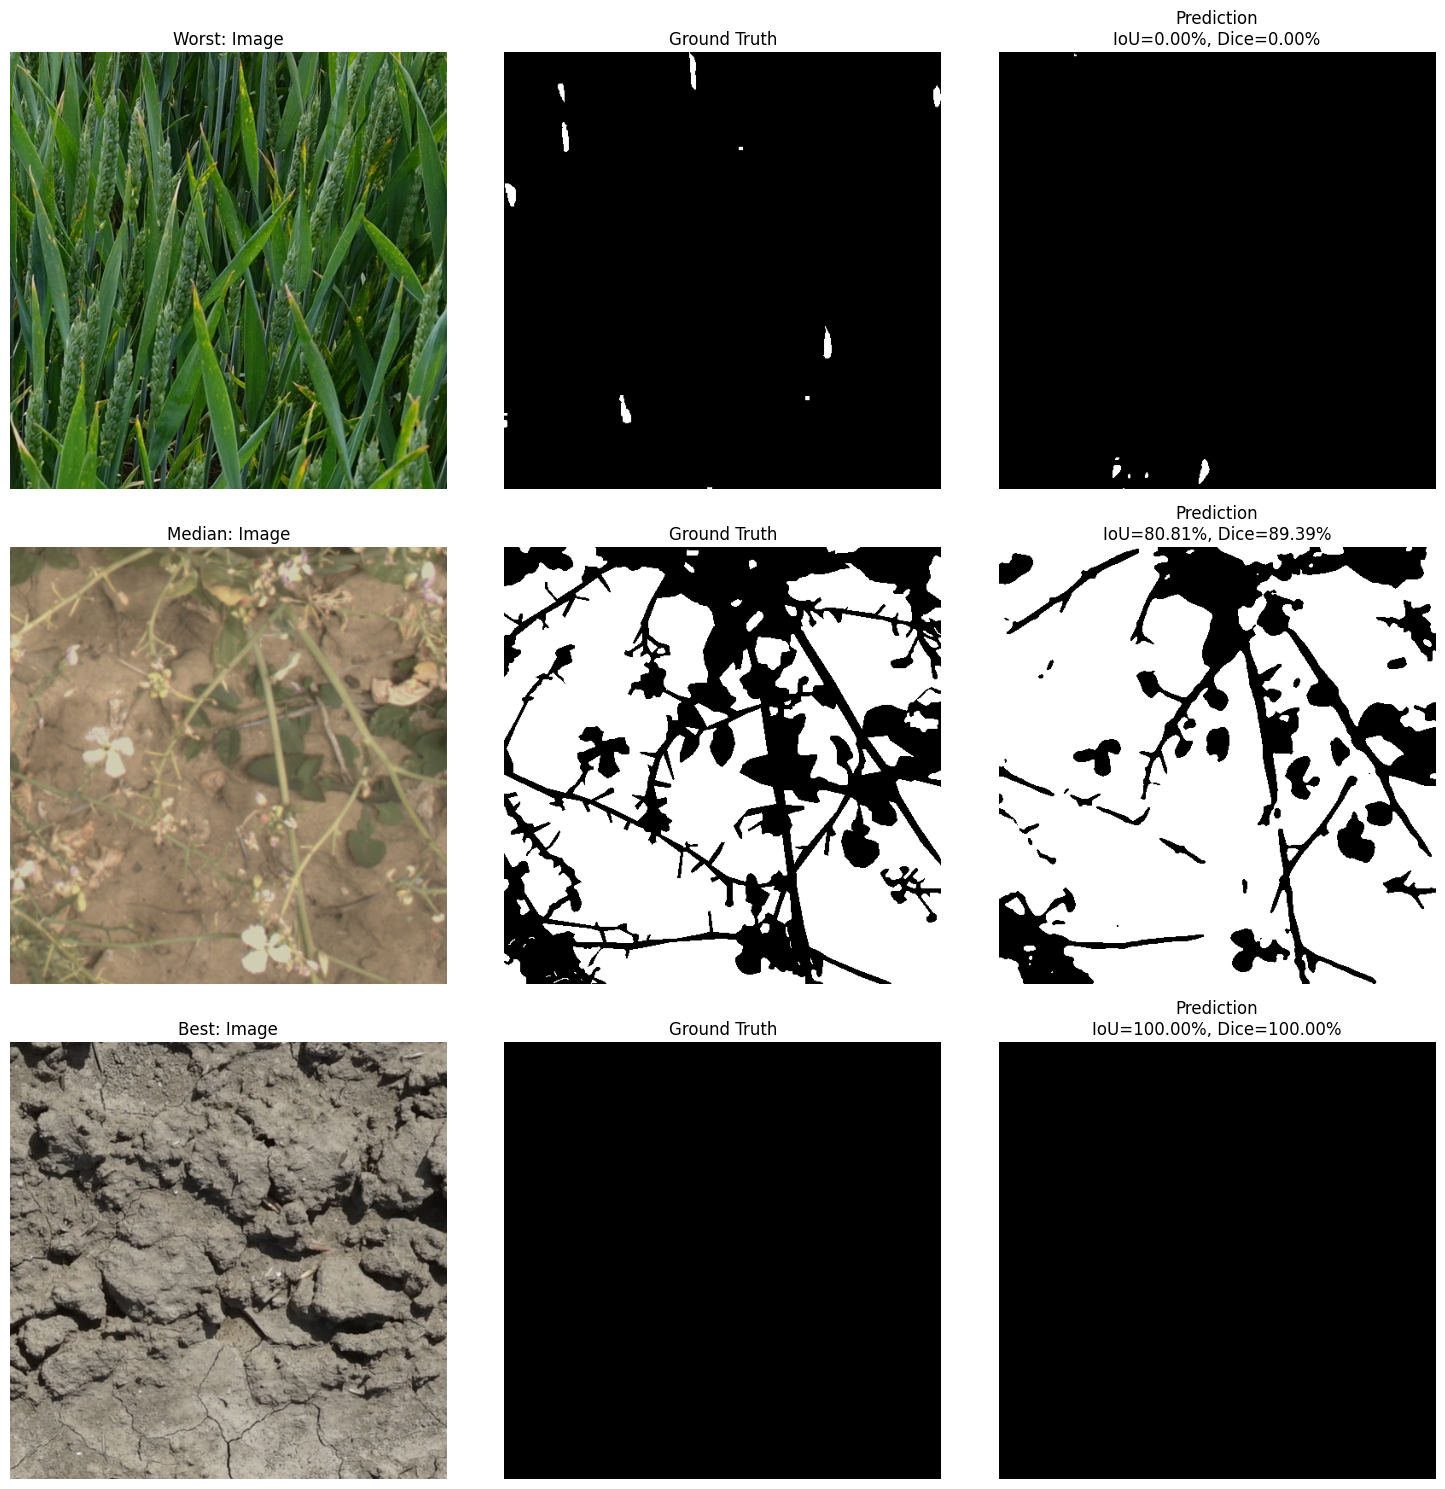

In [41]:
#Visualize all 3 
example_indices = [
    worst_idx,
    median_idx,
    best_idx
]

example_names = [
    "Worst",
    "Median",
    "Best"
]

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 15)
)

for row, (idx, name) in enumerate(
    zip(example_indices, example_names)
):
    image_vis, gt_vis, pred_vis, iou, dice = (
        predict_single_image(
            model,
            val_dataset,
            idx
        )
    )

    axes[row, 0].imshow(image_vis)
    axes[row, 0].set_title(f"{name}: Image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        gt_vis,
        cmap="gray"
    )
    axes[row, 1].set_title("Ground Truth")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(
        pred_vis,
        cmap="gray"
    )
    axes[row, 2].set_title(
        f"Prediction\n"
        f"IoU={iou*100:.2f}%, "
        f"Dice={dice*100:.2f}%"
    )
    axes[row, 2].axis("off")

plt.tight_layout()

plt.savefig(
    "unet_best_median_worst.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()